In [1]:
import os
import time
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from collections import Counter

from torch import nn, optim
from torch.utils.data import DataLoader

from torchvision import transforms, datasets

import kornia.augmentation as K

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.utils.class_weight import compute_class_weight


In [2]:

torch.backends.cudnn.benchmark = True
torch.set_float32_matmul_precision("high")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [3]:
train_path = r"/kaggle/input/datasets/bmuthukumar07/seed-data/data/train"

val_path = r"/kaggle/input/datasets/bmuthukumar07/seed-data/data/val"

In [4]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [5]:
train_set = datasets.ImageFolder(
    root = train_path,
    transform = train_transform
)

test_set = datasets.ImageFolder(
    root = val_path,
    transform = test_transform
)

classes = train_set.classes
num_classes = len(classes)


In [6]:
train_count = Counter(train_set.targets)
test_count = Counter(test_set.targets)

print("=" * 55)
print("Dataset Distribution")
print("=" * 55)

for i, cls in enumerate(classes):
    print(
        f"{cls:<15}"
        f"Train: {train_count[i]:5}"
        f" | Val: {test_count[i]:5}"
    )

print("=" * 55)
print(f"Total Train Images : {len(train_set)}")
print(f"Total Val Images   : {len(test_set)}")

Dataset Distribution
broken         Train:  4554 | Val:  1116
discolored     Train:  2504 | Val:   611
pure           Train:  5855 | Val:  1428
silkcut        Train:  1427 | Val:   324
Total Train Images : 14340
Total Val Images   : 3479


In [7]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_set,
    batch_size = BATCH_SIZE,
    shuffle = True,
    num_workers = 4,
    pin_memory = True,
    persistent_workers = True
)

test_loader = DataLoader(
    test_set,
    batch_size = BATCH_SIZE,
    shuffle = False,
    num_workers = 4,
    pin_memory = True,
    persistent_workers = True
)

In [8]:
gpu_aug = nn.Sequential(

    K.RandomResizedCrop(
        size=(224,224),
        scale=(0.75,1.0),
        ratio=(0.8,1.2)
    ),

    K.RandomHorizontalFlip(p=0.5),

    K.RandomRotation(
        degrees=20,
        p=0.5
    ),

    K.RandomAffine(
        degrees=0,
        translate=(0.1,0.1),
        scale=(0.9,1.1),
        p=0.5
    ),

    K.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.3,
        hue=0.05,
        p=0.6
    ),

    K.RandomGaussianBlur(
        kernel_size=(3,3),
        sigma=(0.1,2.0),
        p=0.2
    ),

    K.RandomSharpness(
        sharpness=0.4,
        p=0.2
    ),

    K.Normalize(
        mean=torch.tensor([0.485,0.456,0.406]),
        std=torch.tensor([0.229,0.224,0.225])
    )

).to(device)

In [9]:
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights
weights = MobileNet_V3_Large_Weights.DEFAULT
model = mobilenet_v3_large(weights=weights)

for param in model.features[:10].parameters():
    param.requires_grad = False

in_features = model.classifier[3].in_features

model.classifier[3] = nn.Sequential(
    nn.Linear(in_features, 512),
    nn.BatchNorm1d(512),
    nn.Hardswish(),
    nn.Dropout(0.5),
    
    nn.Linear(512,256),
    nn.BatchNorm1d(256),
    nn.Hardswish(),

    nn.Dropout(0.3),
    nn.Linear(256, num_classes)
)


model = model.to(device)

trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)


total_params = sum(p.numel() for p in model.parameters())

non_trainable_params = total_params - trainable_params

print(f"Trainable Parameters : {trainable_params:,}")
print(f"Non Trainable Parameters : {non_trainable_params:,}")
print(f"Total Parameters     : {total_params:,}")


Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 132MB/s] 


Trainable Parameters : 4,831,844
Non Trainable Parameters : 159,952
Total Parameters     : 4,991,796


In [10]:
criterion = nn.CrossEntropyLoss(
    label_smoothing = 0.05
)

optimizer = optim.AdamW(
    [
        {
            "params" : model.features[10:].parameters(),
            "lr" : 5e-5
        },
        {
            "params" : model.classifier.parameters(),
            "lr" : 3e-4
        }
    ],

    weight_decay = 5e-4

    
)

epochs = 40

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer,
    T_0=5,
    T_mult=2,
    eta_min=1e-6
)

In [11]:
scaler = torch.amp.GradScaler("cuda")
train_acc_history = []
val_acc_history = []

train_loss_history = []
val_loss_history = []

best_accuracy = 0.0
best_val_loss = float("inf")

patience = 10
counter = 0

for epoch in range(epochs):

    start_time = time.time()

    # -------------------- TRAINING --------------------

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        images = gpu_aug(images)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda"):

            outputs = model(images)

            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_acc = correct / total
    train_loss = running_loss / len(train_loader)

    train_acc_history.append(train_acc)
    train_loss_history.append(train_loss)

    # ---------------- VALIDATION ----------------

    model.eval()

    correct = 0
    total = 0
    val_running_loss = 0.0

    y_true = []
    y_pred = []

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast("cuda"):

                outputs = model(images)

                loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    val_acc = correct / total
    val_loss = val_running_loss / len(test_loader)

    val_acc_history.append(val_acc)
    val_loss_history.append(val_loss)

    scheduler.step()

    if val_acc > best_accuracy:
        best_val_loss = val_loss
        best_accuracy = val_acc
        torch.save(model.state_dict(),"/kaggle/working/best_mobilenet_v3.pth")
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print(f"\nEarly stopping at epoch {epoch+1}")
            break

    elapsed_time = time.time() - start_time
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Acc: {train_acc:.4f} "
        f"Val Acc: {val_acc:.4f} "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Time: {elapsed_time/60:.2f} min"
    )

print(f"\nBest Validation Loss : {best_val_loss:.4f}")
print(f"Best Validation Accuracy : {best_accuracy:.4f}")

Epoch [1/40] Train Acc: 0.6172 Val Acc: 0.6973 Train Loss: 0.9776 Val Loss: 0.8176 Time: 2.12 min
Epoch [2/40] Train Acc: 0.6976 Val Acc: 0.7255 Train Loss: 0.8275 Val Loss: 0.7501 Time: 0.75 min
Epoch [3/40] Train Acc: 0.7313 Val Acc: 0.7281 Train Loss: 0.7626 Val Loss: 0.7344 Time: 0.75 min
Epoch [4/40] Train Acc: 0.7459 Val Acc: 0.7427 Train Loss: 0.7329 Val Loss: 0.7192 Time: 0.76 min
Epoch [5/40] Train Acc: 0.7591 Val Acc: 0.7471 Train Loss: 0.7069 Val Loss: 0.7056 Time: 0.75 min
Epoch [6/40] Train Acc: 0.7471 Val Acc: 0.7508 Train Loss: 0.7283 Val Loss: 0.7039 Time: 0.75 min
Epoch [7/40] Train Acc: 0.7611 Val Acc: 0.7485 Train Loss: 0.7052 Val Loss: 0.7099 Time: 0.75 min
Epoch [8/40] Train Acc: 0.7709 Val Acc: 0.7695 Train Loss: 0.6873 Val Loss: 0.6809 Time: 0.76 min
Epoch [9/40] Train Acc: 0.7810 Val Acc: 0.7680 Train Loss: 0.6642 Val Loss: 0.6847 Time: 0.75 min
Epoch [10/40] Train Acc: 0.7902 Val Acc: 0.7663 Train Loss: 0.6425 Val Loss: 0.6826 Time: 0.76 min
Epoch [11/40] Train

In [12]:
print("\nAccuracy:",
      accuracy_score(y_true, y_pred))

print(
    classification_report(
        y_true,
        y_pred,
        target_names=classes
    )
)

print(confusion_matrix(
    y_true,
    y_pred
))


Accuracy: 0.7643000862316758
              precision    recall  f1-score   support

      broken       0.78      0.68      0.73      1116
  discolored       0.64      0.68      0.66       611
        pure       0.81      0.87      0.84      1428
     silkcut       0.73      0.72      0.73       324

    accuracy                           0.76      3479
   macro avg       0.74      0.74      0.74      3479
weighted avg       0.76      0.76      0.76      3479

[[ 764  125  186   41]
 [  90  416   78   27]
 [ 101   64 1246   17]
 [  20   43   28  233]]


In [13]:
# Load saved weights
WEIGHTS_PATH = "//kaggle/working/best_mobilenet_v3.pth"

model.load_state_dict(
    torch.load(
        WEIGHTS_PATH,
        map_location=device
    )
)

model = model.to(device)
model.eval()

print("Saved weights loaded successfully!")

Saved weights loaded successfully!


In [14]:
%pip install -q grad-cam shap lime captum scikit-learn seaborn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
from scipy.ndimage import gaussian_filter
from skimage.segmentation import mark_boundaries

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

from captum.attr import IntegratedGradients, Occlusion
import shap
from lime import lime_image

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 10.1 MB/s eta 0:00:0000:01
Note: you may need to restart the kernel to use updated packages.


In [15]:
model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        outputs = model(images)
        probabilities = F.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

if "class_names" not in globals():
    class_names = test_loader.dataset.classes

num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)
print("Test samples:", len(all_labels))

Classes: ['broken', 'discolored', 'pure', 'silkcut']
Number of classes: 4
Test samples: 3479


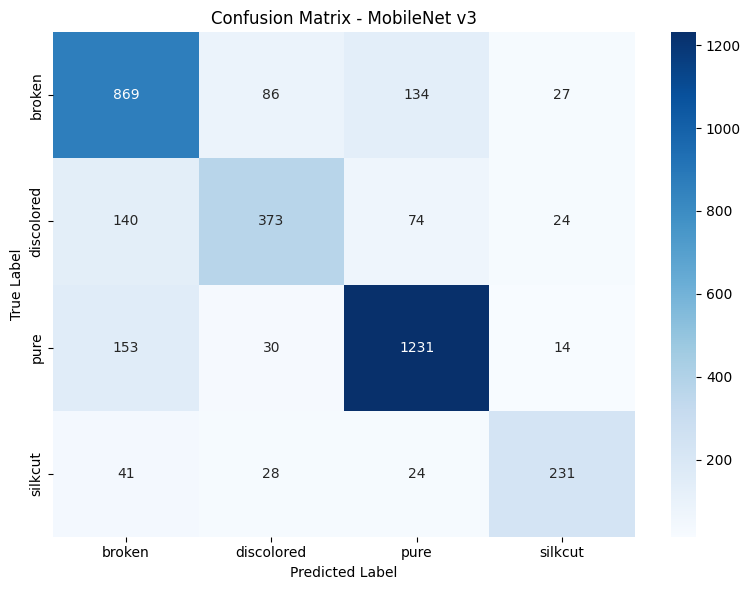

In [16]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - MobileNet v3")
plt.tight_layout()
plt.show()

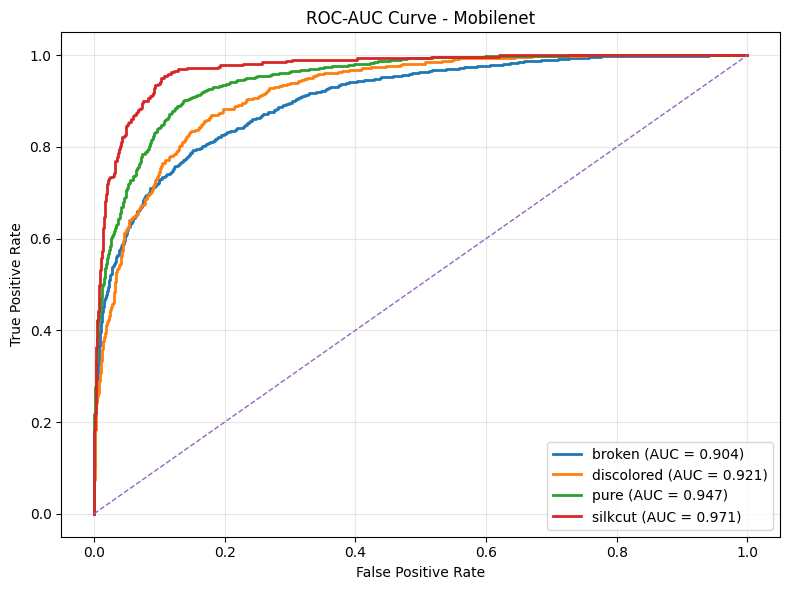

In [17]:
y_true_onehot = np.eye(num_classes)[all_labels]

plt.figure(figsize=(8, 6))

for i in range(num_classes):
    fpr, tpr, _ = roc_curve(
        y_true_onehot[:, i],
        all_probabilities[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_names[i]} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curve - Mobilenet")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

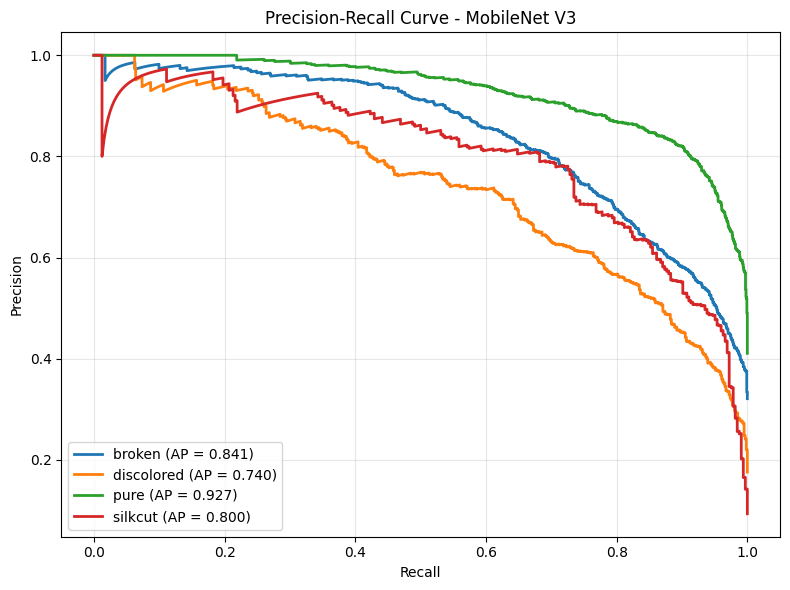

In [18]:
plt.figure(figsize=(8, 6))

for i in range(num_classes):
    precision, recall, _ = precision_recall_curve(
        y_true_onehot[:, i],
        all_probabilities[:, i]
    )

    ap = average_precision_score(
        y_true_onehot[:, i],
        all_probabilities[:, i]
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{class_names[i]} (AP = {ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - MobileNet V3")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
model.eval()

xai_image = None
xai_label = None
xai_prediction = None

for images, labels in test_loader:
    images = images.to(device, non_blocking=True)

    with torch.no_grad():
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

    correct_indices = torch.where(predictions == labels.to(device))[0]

    if len(correct_indices) > 0:
        idx = correct_indices[0].item()

        xai_image = images[idx:idx + 1]
        xai_label = labels[idx].item()
        xai_prediction = predictions[idx].item()
        break

if xai_image is None:
    images, labels = next(iter(test_loader))

    xai_image = images[0:1].to(device)
    xai_label = labels[0].item()

    with torch.no_grad():
        xai_prediction = model(xai_image).argmax(dim=1).item()

print("True class:", class_names[xai_label])
print("Predicted class:", class_names[xai_prediction])

True class: broken
Predicted class: broken


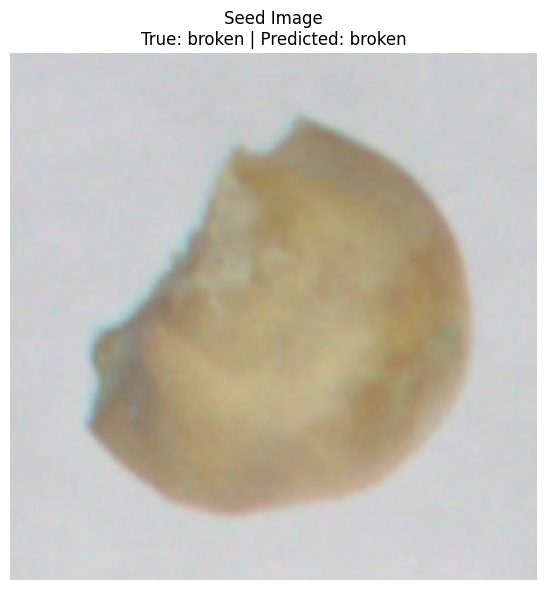

In [20]:

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image_display = (
    xai_image[0]
    .detach()
    .cpu()
    .permute(1, 2, 0)
    .numpy()
)

# Properly undo ImageNet normalization
image_display = (
    image_display * std
) + mean

image_display = np.clip(
    image_display,
    0,
    1
)

plt.figure(figsize=(6, 6))

plt.imshow(image_display)

plt.axis("off")

plt.title(
    f"Seed Image\n"
    f"True: {class_names[xai_label]} | "
    f"Predicted: {class_names[xai_prediction]}"
)

plt.tight_layout()
plt.show()

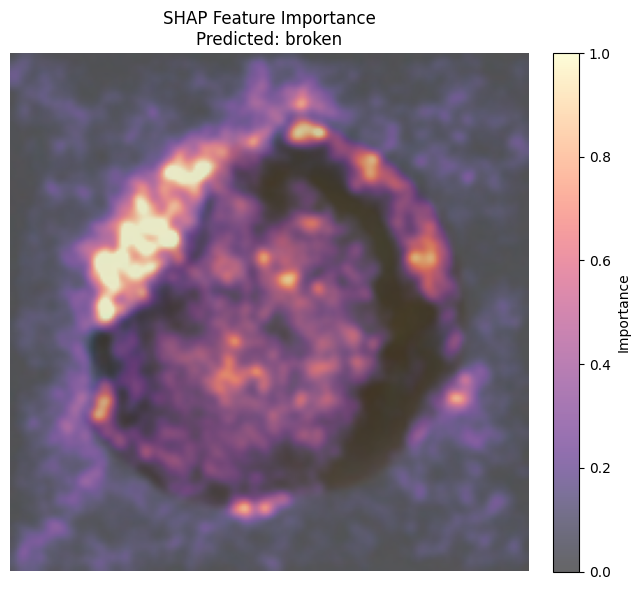

In [21]:
model.eval()

background = next(iter(test_loader))[0][:2].to(device)

class SHAPTargetModel(nn.Module):

    def __init__(self, model, target_class):
        super().__init__()
        self.model = model
        self.target_class = target_class

    def forward(self, x):
        output = self.model(x)

        return output[
            :,
            self.target_class:self.target_class + 1
        ]


shap_model = SHAPTargetModel(
    model,
    xai_prediction
).to(device)

explainer = shap.GradientExplainer(
    shap_model,
    background
)

shap_values = explainer.shap_values(
    xai_image
)

if isinstance(shap_values, list):
    shap_values = shap_values[0]

shap_values = np.asarray(shap_values)

# Remove unnecessary dimensions
shap_values = np.squeeze(shap_values)

if shap_values.ndim == 3:

    if shap_values.shape[0] in [1, 3]:
        shap_map = np.mean(
            np.abs(shap_values),
            axis=0
        )
    else:
        shap_map = np.mean(
            np.abs(shap_values),
            axis=-1
        )

# Smooth pixel-level noise
shap_map = gaussian_filter(
    shap_map,
    sigma=2
)

# Robust normalization
low = np.percentile(
    shap_map,
    5
)

high = np.percentile(
    shap_map,
    99
)

shap_map = np.clip(
    (shap_map - low) / (high - low + 1e-8),
    0,
    1
)

plt.figure(figsize=(7, 6))

plt.imshow(
    image_display
)

plt.imshow(
    shap_map,
    cmap="magma",
    alpha=0.60,
    vmin=0,
    vmax=1
)

plt.axis("off")

plt.title(
    f"SHAP Feature Importance\n"
    f"Predicted: {class_names[xai_prediction]}"
)

plt.colorbar(
    fraction=0.046,
    pad=0.04,
    label="Importance"
)

plt.tight_layout()
plt.show()

  0%|          | 0/1000 [00:00<?, ?it/s]

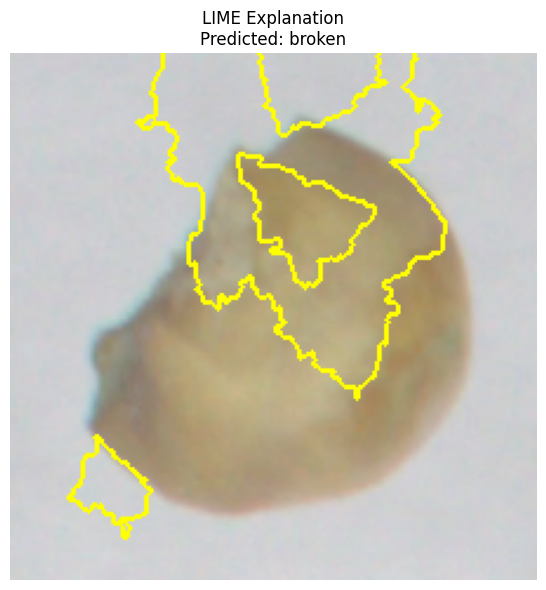

In [22]:
# ============================================================
# IMPROVED LIME
# ============================================================

def lime_predict(images):

    batch = []

    for image in images:

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        image = image.permute(
            2, 0, 1
        )

        image = image / 255.0

        image = transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )(image)

        batch.append(image)

    batch = torch.stack(batch).to(device)

    with torch.no_grad():

        outputs = model(batch)

        probabilities = F.softmax(
            outputs,
            dim=1
        )

    return probabilities.cpu().numpy()


lime_explainer = lime_image.LimeImageExplainer(
    verbose=False
)

lime_input = (
    image_display * 255
).astype(np.uint8)

lime_result = lime_explainer.explain_instance(
    lime_input,
    lime_predict,
    top_labels=1,
    hide_color=0,
    num_samples=1000
)

lime_label = lime_result.top_labels[0]

lime_result_image, lime_mask = (
    lime_result.get_image_and_mask(
        lime_label,
        positive_only=True,
        num_features=8,
        hide_rest=False
    )
)

# Create clean boundary visualization
lime_boundary = mark_boundaries(
    lime_result_image,
    lime_mask,
    color=(1, 1, 0),
    mode="thick"
)

plt.figure(figsize=(7, 6))

plt.imshow(
    lime_boundary
)

plt.axis("off")

plt.title(
    f"LIME Explanation\n"
    f"Predicted: {class_names[xai_prediction]}"
)

plt.tight_layout()
plt.show()

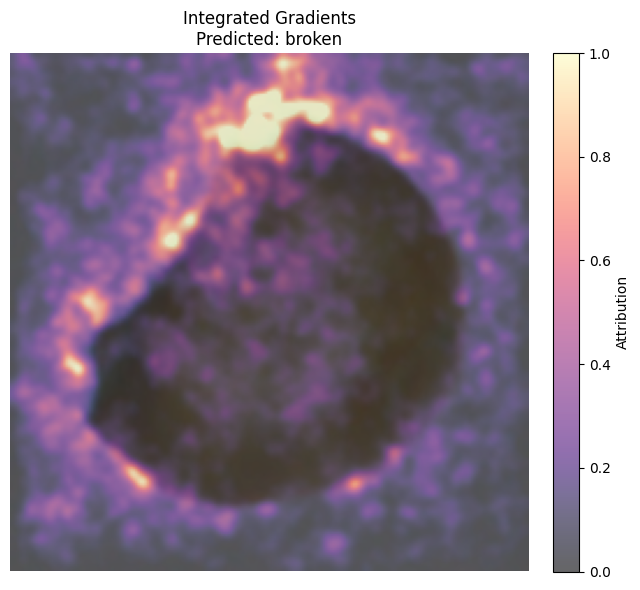

In [23]:


model.eval()

ig = IntegratedGradients(model)

baseline = torch.zeros_like(
    xai_image
)

ig_attributions = ig.attribute(
    xai_image,
    baselines=baseline,
    target=xai_prediction,
    n_steps=64
)

ig_map = (
    ig_attributions[0]
    .detach()
    .cpu()
    .numpy()
)

# Channel aggregation
ig_map = np.mean(
    np.abs(ig_map),
    axis=0
)

# Remove high-frequency noise
ig_map = gaussian_filter(
    ig_map,
    sigma=2
)

# Robust normalization
low = np.percentile(
    ig_map,
    5
)

high = np.percentile(
    ig_map,
    99
)

ig_map = np.clip(
    (ig_map - low) /
    (high - low + 1e-8),
    0,
    1
)

plt.figure(figsize=(7, 6))

plt.imshow(
    image_display
)

plt.imshow(
    ig_map,
    cmap="magma",
    alpha=0.60,
    vmin=0,
    vmax=1
)

plt.axis("off")

plt.title(
    f"Integrated Gradients\n"
    f"Predicted: {class_names[xai_prediction]}"
)

plt.colorbar(
    fraction=0.046,
    pad=0.04,
    label="Attribution"
)

plt.tight_layout()
plt.show()

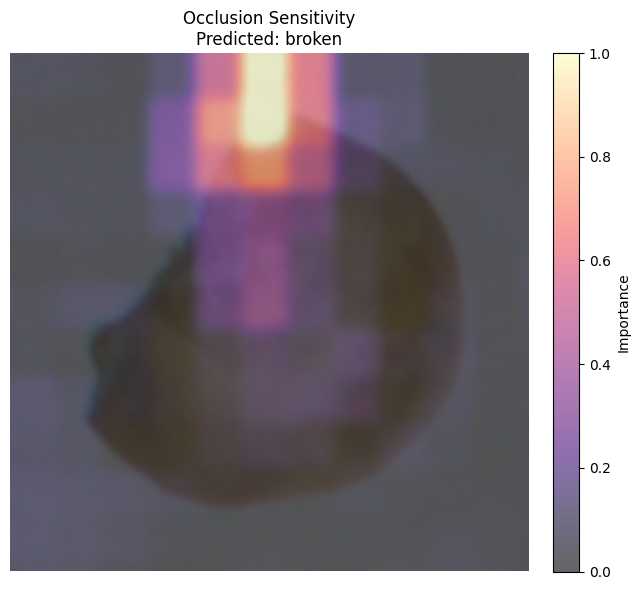

In [24]:
# ============================================================
# IMPROVED OCCLUSION SENSITIVITY
# ============================================================

model.eval()

occlusion = Occlusion(model)

occlusion_attributions = occlusion.attribute(
    xai_image,
    target=xai_prediction,
    strides=(3, 20, 20),
    sliding_window_shapes=(3, 40, 40),
    baselines=0
)

occlusion_map = (
    occlusion_attributions[0]
    .detach()
    .cpu()
    .numpy()
)

occlusion_map = np.mean(
    np.abs(occlusion_map),
    axis=0
)

# Smooth the grid effect
occlusion_map = gaussian_filter(
    occlusion_map,
    sigma=3
)

# Robust normalization
low = np.percentile(
    occlusion_map,
    5
)

high = np.percentile(
    occlusion_map,
    99
)

occlusion_map = np.clip(
    (occlusion_map - low) /
    (high - low + 1e-8),
    0,
    1
)

plt.figure(figsize=(7, 6))

plt.imshow(
    image_display
)

plt.imshow(
    occlusion_map,
    cmap="magma",
    alpha=0.60,
    vmin=0,
    vmax=1
)

plt.axis("off")

plt.title(
    f"Occlusion Sensitivity\n"
    f"Predicted: {class_names[xai_prediction]}"
)

plt.colorbar(
    fraction=0.046,
    pad=0.04,
    label="Importance"
)

plt.tight_layout()
plt.show()